# Telecom Customer Churn Prediction

An end-to-end Data Science project: understand why telecom customers leave, and build a model that flags customers who are at risk of leaving.

**Notebook outline**

1. Business problem and objectives
2. Imports and setup
3. Dataset understanding
4. Data cleaning and preparation
5. Exploratory data analysis (EDA)
6. Feature engineering and preprocessing
7. Baseline model
8. Training machine learning models
9. Model evaluation
10. Feature importance and interpretation
11. Business insights and recommendations
12. Limitations and future improvements
13. Final summary

## 1. Business Problem and Objectives

**What is churn?** In telecommunications, *churn* means a customer cancels their service and leaves the company. Here, the target column `Churn` records whether a customer left (`Yes`) or stayed (`No`).

**Why does it matter?** Winning a new customer usually costs more than keeping an existing one (advertising, sales effort, device subsidies, set-up costs). A telecom company that can spot customers who are *likely to leave* has a chance to act first, for example with a better plan, a contract offer, or a support call. Without that warning, it only finds out after the customer is gone.

**The business problem.** The retention team has limited time and budget, so it cannot contact everyone. It needs to know (a) which kinds of customers leave most often, and (b) which individual customers it should prioritise.

**Objectives of this project**

*Analytical*
- Measure what share of customers churned.
- Find which customer characteristics (contract type, tenure, charges, payment method, services) are associated with higher or lower churn.
- Identify customer groups that look most at risk.

*Predictive*
- Build a classification model that estimates each customer's probability of churning.
- Compare it against a naive baseline and judge it with metrics that suit an imbalanced problem, not accuracy alone.
- Turn the findings into practical retention recommendations, being careful to separate *what the data shows* from *what would still need testing*.

## 2. Imports and Setup

We only import what the project uses: Pandas/NumPy for data, Matplotlib/Seaborn for charts, and Scikit-learn for preprocessing, models and evaluation. A fixed `RANDOM_STATE` makes every random step (data split, model training) repeatable.

Paths are built relative to the project folder, so the notebook works wherever the repository is cloned. It works whether Jupyter is started from the project root or from the `notebooks/` folder.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, make_scorer,
    classification_report, roc_curve, precision_recall_curve, confusion_matrix,
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

# Project paths (relative, so the notebook runs from the repo root or from notebooks/)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "telecom_churn.csv"
CHARTS_DIR = PROJECT_ROOT / "charts"
CHARTS_DIR.mkdir(exist_ok=True)

# Consistent chart style
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.titlesize": 13, "axes.labelsize": 11, "figure.dpi": 100})
CHURN_COLORS = {"No": "#4C78A8", "Yes": "#E45756"}   # blue = stayed, red = churned


def save_chart(fig, filename):
    """Save a figure into charts/ and tell us where it went."""
    fig.savefig(CHARTS_DIR / filename, dpi=150, bbox_inches="tight", facecolor="white")
    print(f"Saved: charts/{filename}")


print("Project root:", PROJECT_ROOT.name)
print("Raw data found:", RAW_DATA_PATH.exists())

Project root: telecom-churn-prediction
Raw data found: True


## 3. Dataset Understanding

**What we are doing:** looking at the raw data before changing anything.
**Why:** cleaning decisions and modelling choices should come from evidence. We check the size, column types, missing values, duplicates, and how the target is distributed.

Nothing here modifies the file on disk. We load it into `df_raw` and keep that untouched; cleaning happens later on a copy.

In [2]:
df_raw = pd.read_csv(RAW_DATA_PATH)

print(f"Rows: {df_raw.shape[0]:,}   Columns: {df_raw.shape[1]}")
df_raw.head()

Rows: 7,043   Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Column names, data types, missing values and number of distinct values
column_overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "unique_values": df_raw.nunique(),
})
column_overview

,dtype,missing,unique_values
customerID,str,0,7043
gender,str,0,2
SeniorCitizen,int64,0,2
Partner,str,0,2
Dependents,str,0,2
tenure,int64,0,73
PhoneService,str,0,2
MultipleLines,str,0,3
InternetService,str,0,3
OnlineSecurity,str,0,3


In [4]:
# Duplicates: exact duplicate rows, repeated customer IDs, and identical profiles
print("Fully duplicated rows:                          ", df_raw.duplicated().sum())
print("Repeated customerID values:                     ", df_raw["customerID"].duplicated().sum())
print("Rows identical on every column except customerID:", df_raw.drop(columns="customerID").duplicated().sum())

Fully duplicated rows:                           0
Repeated customerID values:                      0
Rows identical on every column except customerID: 22


In [5]:
# Summary statistics for the numeric columns
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [6]:
# Target variable: how many customers churned?
churn_counts = df_raw["Churn"].value_counts()
churn_share = df_raw["Churn"].value_counts(normalize=True).mul(100).round(1)
pd.DataFrame({"customers": churn_counts, "percent": churn_share})

,customers,percent
Churn,,
No,5174,73.5
Yes,1869,26.5


In [7]:
# Distinct values of every categorical column (except the ID)
categorical_overview = [c for c in df_raw.columns if df_raw[c].dtype != "int64" and df_raw[c].dtype != "float64"
                        and c not in ("customerID", "TotalCharges")]
for column in categorical_overview:
    values = df_raw[column].value_counts().to_dict()
    print(f"{column:18s} {values}")

gender             {'Male': 3555, 'Female': 3488}
Partner            {'No': 3641, 'Yes': 3402}
Dependents         {'No': 4933, 'Yes': 2110}
PhoneService       {'Yes': 6361, 'No': 682}
MultipleLines      {'No': 3390, 'Yes': 2971, 'No phone service': 682}
InternetService    {'Fiber optic': 3096, 'DSL': 2421, 'No': 1526}
OnlineSecurity     {'No': 3498, 'Yes': 2019, 'No internet service': 1526}
OnlineBackup       {'No': 3088, 'Yes': 2429, 'No internet service': 1526}
DeviceProtection   {'No': 3095, 'Yes': 2422, 'No internet service': 1526}
TechSupport        {'No': 3473, 'Yes': 2044, 'No internet service': 1526}
StreamingTV        {'No': 2810, 'Yes': 2707, 'No internet service': 1526}
StreamingMovies    {'No': 2785, 'Yes': 2732, 'No internet service': 1526}
Contract           {'Month-to-month': 3875, 'Two year': 1695, 'One year': 1473}
PaperlessBilling   {'Yes': 4171, 'No': 2872}
PaymentMethod      {'Electronic check': 2365, 'Mailed check': 1612, 'Bank transfer (automatic)': 1544, 'Credit 

### Data-quality checks

Two things from the output above deserve a closer look:

1. `TotalCharges` is stored as text (`str`/`object`) even though it should be a number.
2. Several service columns contain labels such as `No internet service` and `No phone service`.

We investigate both before deciding what to do.

In [8]:
# 1) TotalCharges: which values cannot be converted to a number?
total_charges_numeric = pd.to_numeric(df_raw["TotalCharges"], errors="coerce")
invalid_total_charges = df_raw[total_charges_numeric.isna()]

print("TotalCharges values that are not valid numbers:", len(invalid_total_charges))
print("What those raw values look like:", [repr(v) for v in invalid_total_charges["TotalCharges"].unique()])
invalid_total_charges[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

TotalCharges values that are not valid numbers: 11
What those raw values look like: ["' '"]


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [9]:
# 2) Are the "No internet service" / "No phone service" labels just a restatement of another column?
internet_dependent = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
no_internet = df_raw["InternetService"].eq("No")
for column in internet_dependent:
    matches = (df_raw[column].eq("No internet service") == no_internet).all()
    print(f"{column:17s} 'No internet service' appears exactly when InternetService == 'No': {matches}")

no_phone = df_raw["PhoneService"].eq("No")
print(f"{'MultipleLines':17s} 'No phone service' appears exactly when PhoneService == 'No':     "
      f"{(df_raw['MultipleLines'].eq('No phone service') == no_phone).all()}")

# 3) Is TotalCharges roughly tenure x MonthlyCharges? (it should be, if both are billed amounts)
valid = total_charges_numeric.notna()
print("\nCorrelation between TotalCharges and tenure x MonthlyCharges:",
      round(np.corrcoef(total_charges_numeric[valid], (df_raw["tenure"] * df_raw["MonthlyCharges"])[valid])[0, 1], 3))

OnlineSecurity    'No internet service' appears exactly when InternetService == 'No': True
OnlineBackup      'No internet service' appears exactly when InternetService == 'No': True
DeviceProtection  'No internet service' appears exactly when InternetService == 'No': True
TechSupport       'No internet service' appears exactly when InternetService == 'No': True
StreamingTV       'No internet service' appears exactly when InternetService == 'No': True
StreamingMovies   'No internet service' appears exactly when InternetService == 'No': True
MultipleLines     'No phone service' appears exactly when PhoneService == 'No':     True

Correlation between TotalCharges and tenure x MonthlyCharges: 1.0


### What the inspection shows

- **Size and structure.** 7,043 customers (rows) and 21 columns: one identifier (`customerID`), the target (`Churn`), and 19 candidate features. Three are numeric (`tenure`, `MonthlyCharges`, `TotalCharges`) and the rest are categorical, including `SeniorCitizen`, which is coded `0/1`.
- **Target.** 5,174 customers stayed (73.5%) and 1,869 churned (26.5%): roughly one churner for every 2.8 loyal customers. The classes are imbalanced, but not extremely.
- **Hidden missing values.** `isna()` reports no missing values, but `TotalCharges` is stored as text because 11 rows contain a blank string (a single space). All 11 belong to customers with `tenure = 0` who did not churn, i.e. brand-new customers who had not been billed yet. This is a reminder to check data types, not only `isna()`.
- **Duplicates.** No duplicated rows and no repeated `customerID`. 22 rows have an identical profile to another row apart from the ID; they are different customers who happen to share the same attributes, so they stay.
- **Redundant labels.** `No internet service` appears in six columns exactly when `InternetService` is `No`, and `No phone service` appears exactly when `PhoneService` is `No`. They are consistent, not errors, but they repeat information that is already in another column.
- **Overlapping numeric features.** `TotalCharges` is almost exactly `tenure x MonthlyCharges` (correlation of about 1.0 in the check above), so it carries little independent information. This is *multicollinearity*, not leakage, but it will matter when we interpret model coefficients.
- **Possible leakage.** No column records the outcome of the churn process itself (no cancellation date or reason), so the dataset has no obvious leaking feature. The leakage risks come from our own handling (keeping the ID or the text `Churn` column in the inputs, or fitting preprocessing before splitting), which Section 6 addresses. One caveat remains: the file is a single snapshot with no dates, so for customers who left, `tenure` is the time they stayed *before* leaving (see Section 12).

### Verified facts vs. assumptions

**Verified from the file:** everything listed above. **Not verified:** where the data comes from, when it was collected, which company or region it represents, and whether it is real or synthetic. The file has the same layout as a widely shared "Telco Customer Churn" sample dataset, but the file itself carries no documentation, so this project treats it as a realistic example for demonstrating the workflow rather than as evidence about any real company.

## 4. Data Cleaning and Preparation

**What we are doing:** fixing only the problems we found, on a copy of the data.
**Why:** each change below is backed by evidence from Section 3, and the raw data stays unmodified.

| Issue found | Decision |
|---|---|
| `TotalCharges` stored as text, with blank values | Convert to a number. Blanks become missing values first, then are filled with `0` (see reasoning below). |
| `SeniorCitizen` coded `0/1` while every other yes/no column uses `Yes/No` | Relabel to `Yes/No` so all yes/no features are handled the same way. |
| `Churn` is text (`Yes`/`No`) | Create a numeric target `ChurnFlag` (`1` = churned, `0` = stayed). The original column is kept for readable charts. |
| `customerID` is an identifier | Kept in the cleaned table for traceability; it is removed from the model inputs in Section 6. |
| `No internet service` / `No phone service` labels | Kept in the cleaned data: they are consistent (not errors) and are informative for EDA. They are collapsed to `No` for modelling in Section 6, because they repeat what `InternetService` / `PhoneService` already say. |
| Duplicate rows | None to remove. 22 rows share an identical profile with another row, but they have different `customerID`s, so they are different customers and are kept. |

**Why fill the blank `TotalCharges` with 0 instead of dropping those rows?** Every blank belongs to a customer with `tenure = 0`, i.e. someone who had not completed a first month and so had not been billed yet. A total billed amount of `0` is a literal description of that situation, not a guess learned from the data, so it cannot leak information from the test set. Dropping the rows would throw away 11 valid customers for no good reason.

In [10]:
df = df_raw.copy()

# Remove accidental whitespace in text columns (defensive; changes nothing if there is none)
text_columns = df.select_dtypes(exclude="number").columns
for column in text_columns:
    df[column] = df[column].str.strip()

# TotalCharges: text -> number. Blank strings become NaN first.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
blank_mask = df["TotalCharges"].isna()
print("Customers with a blank TotalCharges:", blank_mask.sum())
print("Their tenure values:", sorted(df.loc[blank_mask, "tenure"].astype(int).unique().tolist()), "(all zero = not billed yet)")
df.loc[blank_mask, "TotalCharges"] = 0.0

# SeniorCitizen: 0/1 -> No/Yes, consistent with the other yes/no columns
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# Numeric target: 1 = churned, 0 = stayed
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

# Verify the result
print("\nMissing values left:", int(df.isna().sum().sum()))
print("TotalCharges dtype:", df["TotalCharges"].dtype)
print("Target check:", df.groupby("Churn")["ChurnFlag"].agg(["min", "max", "size"]).to_dict("index"))
print("Raw data untouched (still has the blanks):", int(pd.to_numeric(df_raw["TotalCharges"], errors="coerce").isna().sum()))

Customers with a blank TotalCharges: 11
Their tenure values: [0] (all zero = not billed yet)

Missing values left: 0
TotalCharges dtype: float64
Target check: {'No': {'min': 0, 'max': 0, 'size': 5174}, 'Yes': {'min': 1, 'max': 1, 'size': 1869}}
Raw data untouched (still has the blanks): 11


We did not save a separate "processed" CSV. The cleaning is three small changes that run in under a second, so regenerating them from the raw file in this notebook is simpler and avoids having two copies of the data to keep in sync.

## 5. Exploratory Data Analysis (EDA)

**What we are doing:** looking for patterns in who churns.
**Why:** EDA tells us which features are worth attention, helps us sanity-check the data, and gives us the business story that the model should later agree with (or challenge).

**An important habit:** when comparing groups we always use the **churn rate within each group** (churned customers ÷ all customers in that group), not raw counts. A large group can have the most churners simply because it is large. Charts also show the group size `n` so that small groups are not over-interpreted.

Everything below describes *associations*. A group having a higher churn rate does not show that the group's attribute causes churn.

In [11]:
def churn_rate_table(data, column):
    """Customers, churners and churn rate (%) for each value of `column`."""
    table = (data.groupby(column, observed=True)["ChurnFlag"]
                 .agg(customers="size", churned="sum", churn_rate="mean")
                 .reset_index())
    table["churn_rate"] = (table["churn_rate"] * 100).round(1)
    return table


def plot_churn_rate(ax, data, column, order=None, title=None):
    """Horizontal bars of churn rate per category, with n shown, and a dashed line at the overall rate."""
    table = churn_rate_table(data, column)
    if order is None:
        table = table.sort_values("churn_rate", ascending=False)
    else:
        table = table.set_index(column).loc[order].reset_index()
    overall = data["ChurnFlag"].mean() * 100
    ax.barh(table[column].astype(str), table["churn_rate"], color="#E45756", alpha=0.85)
    ax.axvline(overall, color="black", linestyle="--", linewidth=1)
    for y, (rate, n) in enumerate(zip(table["churn_rate"], table["customers"])):
        ax.text(rate + 0.8, y, f"{rate:.1f}%  (n={n:,})", va="center", fontsize=9, zorder=5,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5))
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, max(table["churn_rate"].max() * 1.45, overall * 1.2))
    ax.invert_yaxis()
    ax.set_title(title or column)
    ax.set_xlabel("Churn rate (%)")
    ax.set_ylabel("")

### 5.1 Overall churn distribution

Saved: charts/01_churn_distribution.png


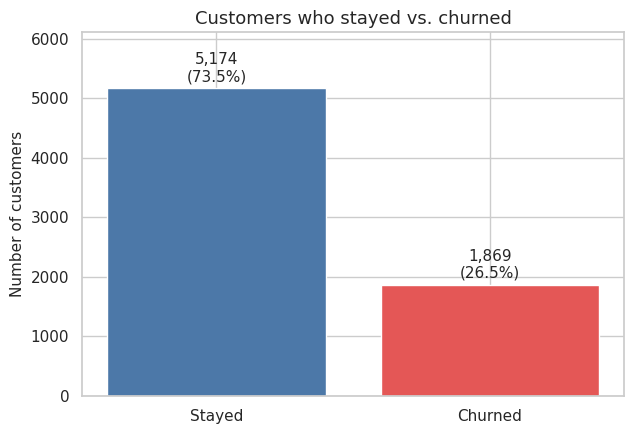

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
order = ["No", "Yes"]
counts = df["Churn"].value_counts().reindex(order)
bars = ax.bar(["Stayed", "Churned"], counts.values, color=[CHURN_COLORS["No"], CHURN_COLORS["Yes"]])
for bar, count in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, count + 60, f"{count:,}\n({count / len(df) * 100:.1f}%)",
            ha="center", va="bottom", fontsize=11)
ax.set_ylim(0, counts.max() * 1.18)
ax.set_title("Customers who stayed vs. churned")
ax.set_ylabel("Number of customers")
plt.tight_layout()
save_chart(fig, "01_churn_distribution.png")
plt.show()

**What the chart shows.** 1,869 of 7,043 customers (26.5%) churned and 5,174 (73.5%) stayed, so about one customer in four left.

**Why this matters (class imbalance).** A model that predicted "stayed" for every customer would be right 73.5% of the time while never finding a single churner. So 73.5% is the accuracy to beat, and we will focus on recall, precision and ROC-AUC for the churn class instead of accuracy.

### 5.2 Numerical features

Saved: charts/02_numerical_feature_distributions.png


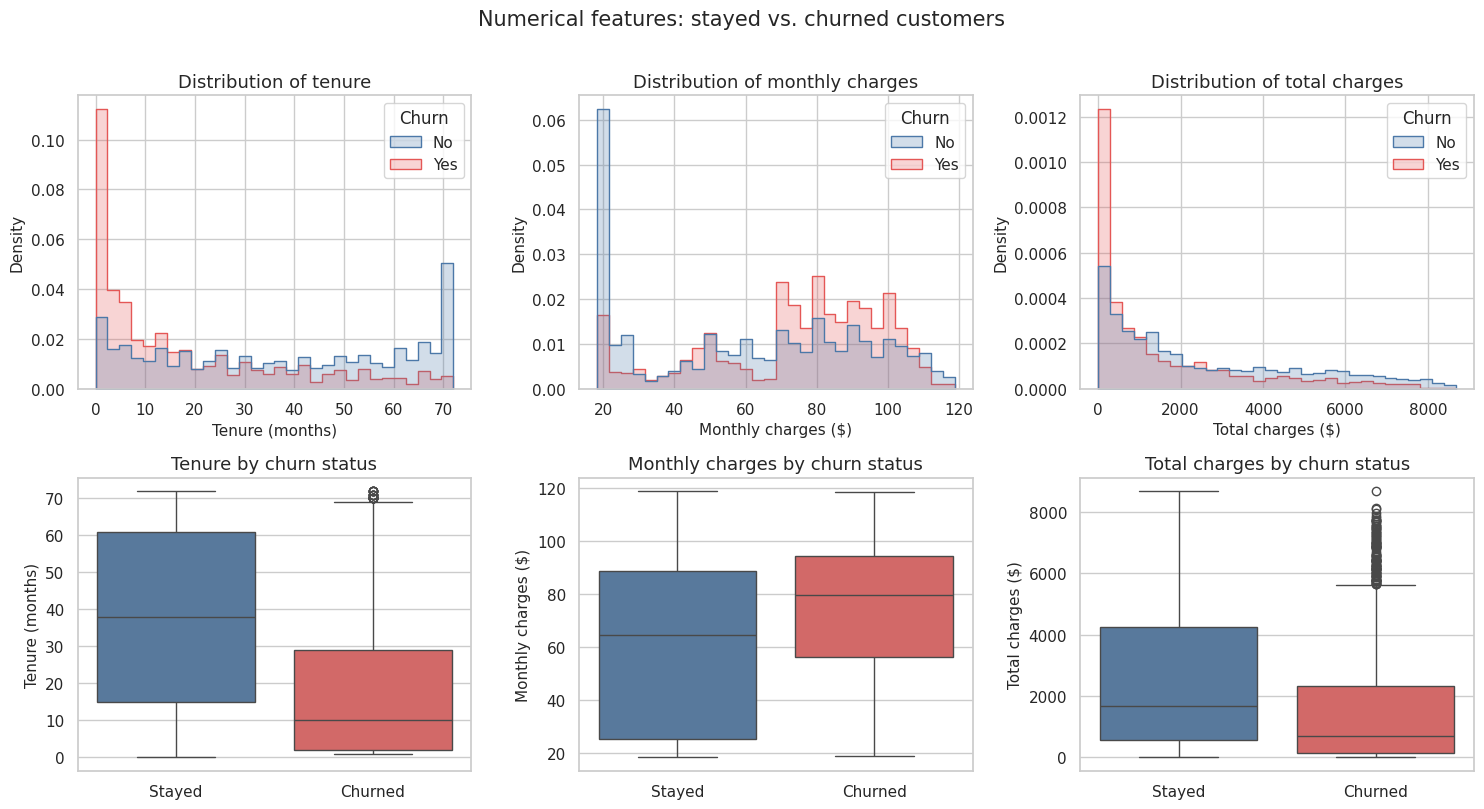

,tenure,MonthlyCharges,TotalCharges
Churn,,,
Stayed (median),38.0,64.4,1679.5
Churned (median),10.0,79.6,703.6


In [13]:
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
labels = {"tenure": "Tenure (months)", "MonthlyCharges": "Monthly charges ($)", "TotalCharges": "Total charges ($)"}
for i, column in enumerate(numeric_features):
    # Top row: distribution, each group scaled to its own size so shapes are comparable
    sns.histplot(data=df, x=column, hue="Churn", hue_order=["No", "Yes"], palette=CHURN_COLORS,
                 stat="density", common_norm=False, element="step", bins=30, ax=axes[0, i])
    axes[0, i].set_title(f"Distribution of {labels[column].split(' (')[0].lower()}")
    axes[0, i].set_xlabel(labels[column])
    # Bottom row: box plots (median, middle 50%, spread)
    sns.boxplot(data=df, x="Churn", y=column, order=["No", "Yes"], hue="Churn", hue_order=["No", "Yes"],
                palette=CHURN_COLORS, legend=False, ax=axes[1, i])
    axes[1, i].set_xticks([0, 1], ["Stayed", "Churned"])
    axes[1, i].set_xlabel("")
    axes[1, i].set_ylabel(labels[column])
    axes[1, i].set_title(f"{labels[column].split(' (')[0]} by churn status")
fig.suptitle("Numerical features: stayed vs. churned customers", fontsize=15, y=1.01)
plt.tight_layout()
save_chart(fig, "02_numerical_feature_distributions.png")
plt.show()

df.groupby("Churn")[numeric_features].median().round(1).rename(index={"No": "Stayed (median)", "Yes": "Churned (median)"})

**What the charts show.** Top row: how each feature is distributed for customers who stayed (blue) and churned (red), each group scaled to its own size. Bottom row: the median, the middle 50% of values and the spread for each group.

**Patterns observed**

- **Tenure.** Churners are much newer customers: median tenure is 10 months versus 38 for customers who stayed (means: 18.0 vs 37.6). 41.9% of churners left within their first 6 months, and only 5.3% of churners had 60 or more months of tenure, compared with 26.7% of customers who stayed.
- **Monthly charges.** Churners pay more per month: median $79.6 vs $64.4 (means: $74.4 vs $61.3). Two-thirds of churners (66.7%) pay between $70 and $110, compared with 41.2% of customers who stayed. Customers who stayed include a large block paying under $30 (28.8% of them, against 8.7% of churners); these are mostly customers without internet service, who pay about $21 a month on average.
- **Total charges.** Churners have lower total charges (median $703.6 vs $1,679.5). This mostly reflects their shorter tenure, since total charges accumulate over time (correlation with tenure is 0.83, see 5.5), and does not mean churners spend less overall.

**Business relevance.** New customers and customers on higher monthly bills show up more often among churners. The monthly-charge pattern is partly a service-type effect (fiber-optic customers pay about $91.5 a month on average versus $58.1 for DSL), so it should be read together with the service patterns below rather than as a pure "price" effect.

### 5.3 Categorical features

One panel per feature. Each bar is the churn rate of that category, and the dashed line is the overall churn rate. Categories to the right of the line churn more than average.

Saved: charts/03_categorical_feature_analysis.png


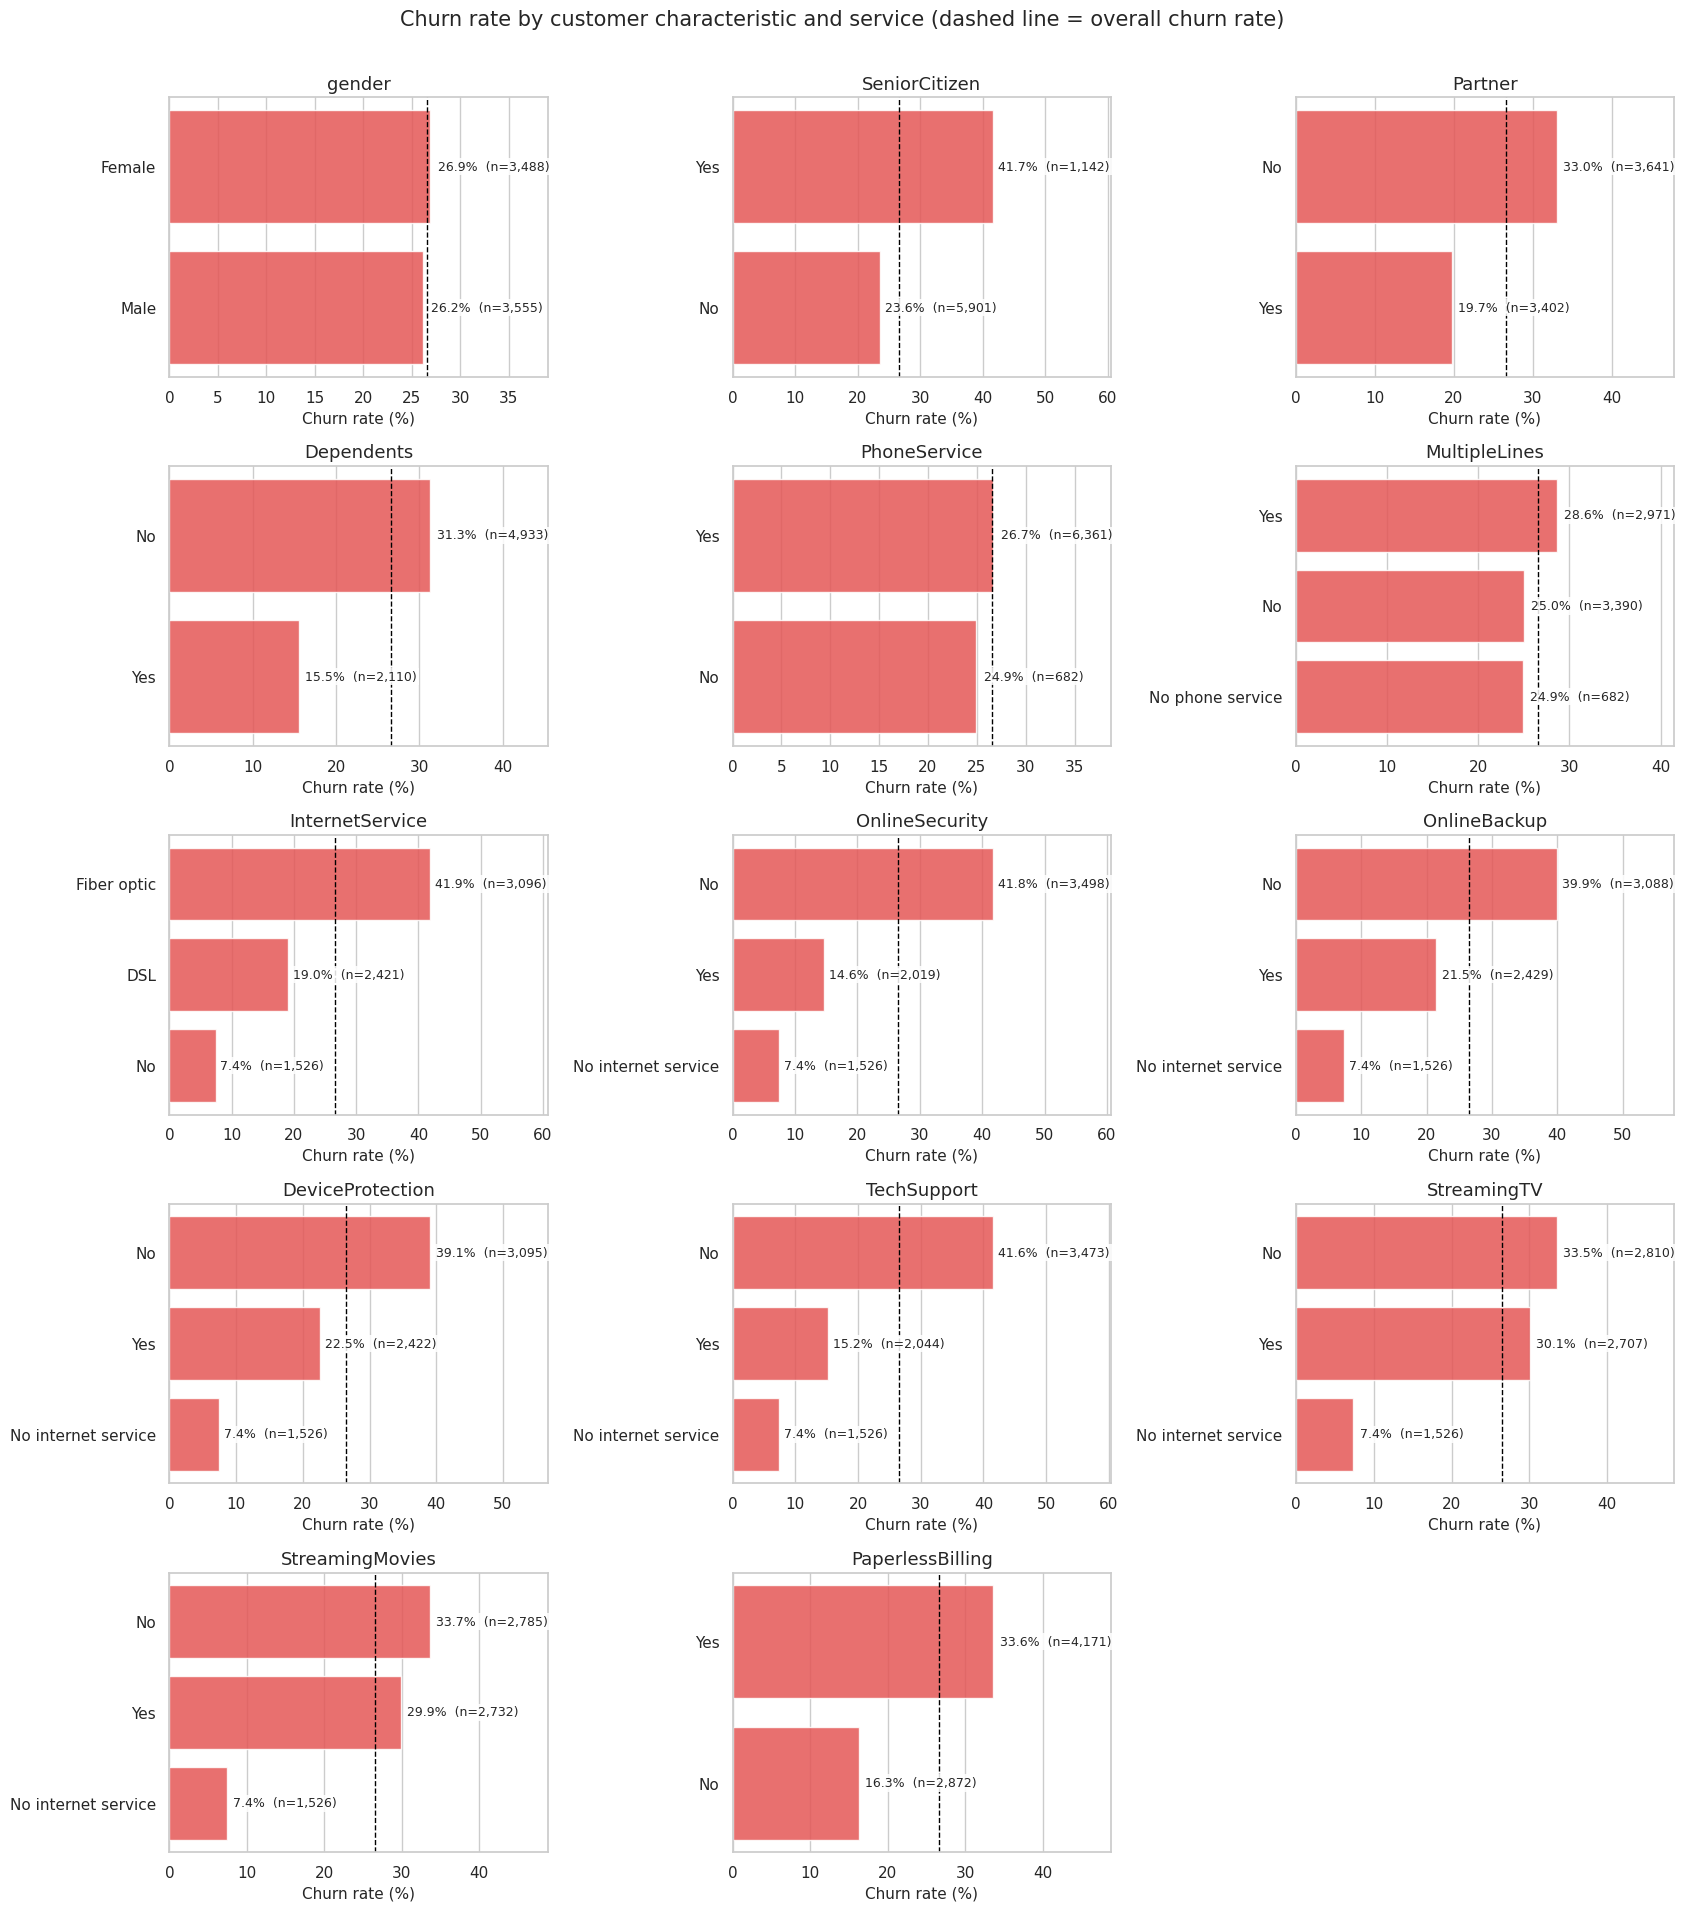

In [14]:
categorical_features_for_eda = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
                                "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                                "TechSupport", "StreamingTV", "StreamingMovies", "PaperlessBilling"]

fig, axes = plt.subplots(5, 3, figsize=(17, 19))
for ax, column in zip(axes.flat, categorical_features_for_eda):
    plot_churn_rate(ax, df, column)
for ax in axes.flat[len(categorical_features_for_eda):]:
    ax.axis("off")
fig.suptitle("Churn rate by customer characteristic and service (dashed line = overall churn rate)", fontsize=15, y=1.005)
plt.tight_layout()
save_chart(fig, "03_categorical_feature_analysis.png")
plt.show()

**What the chart shows.** Each bar is the churn rate within that category (churners ÷ customers in the category); `n` is the category size.

**Patterns observed**

- **Little or no difference:** gender (26.9% female vs 26.2% male), and phone service (26.7% with vs 24.9% without) show little variation. Multiple lines varies only slightly (28.6% vs 25.0%).
- **Senior citizens** churn much more: 41.7% vs 23.6% for non-seniors (1,142 seniors, about 16% of customers).
- **Household ties:** customers with a partner churn at 19.7% (33.0% without), and customers with dependents at 15.5% (31.3% without).
- **Internet service type** shows the largest gap: fiber optic 41.9%, DSL 19.0%, no internet 7.4%. The "No internet service" group (phone-only customers) is the same 1,526 customers in every service panel, which is why the 7.4% bar repeats.
- **Support and protection add-ons:** customers with internet service but *without* online security churn at 41.8% (14.6% with it), without tech support 41.6% (15.2% with), without online backup 39.9% (21.5% with), and without device protection 39.1% (22.5% with).
- **Streaming** barely separates customers: 30.1% (TV) and 29.9% (movies) for subscribers vs 33.5% and 33.7% for non-subscribers.
- **Paperless billing:** 33.6% vs 16.3% for paper billing.

**Business relevance.** The biggest gaps involve the service bundle (fiber, no security or support add-ons) and customer circumstances (seniors, no partner or dependents). Customers who take security and support add-ons may simply be more engaged with the company, so the data does not show that the add-ons themselves reduce churn. That would need testing.

### 5.4 Contract, tenure, payment method and internet service

These are the features most closely tied to the business levers a telecom company controls (what contract it offers, how it bills, which service it sells). Tenure is grouped into four bands so that it can be compared like the other categories.

Saved: charts/04_churn_by_contract_or_key_features.png


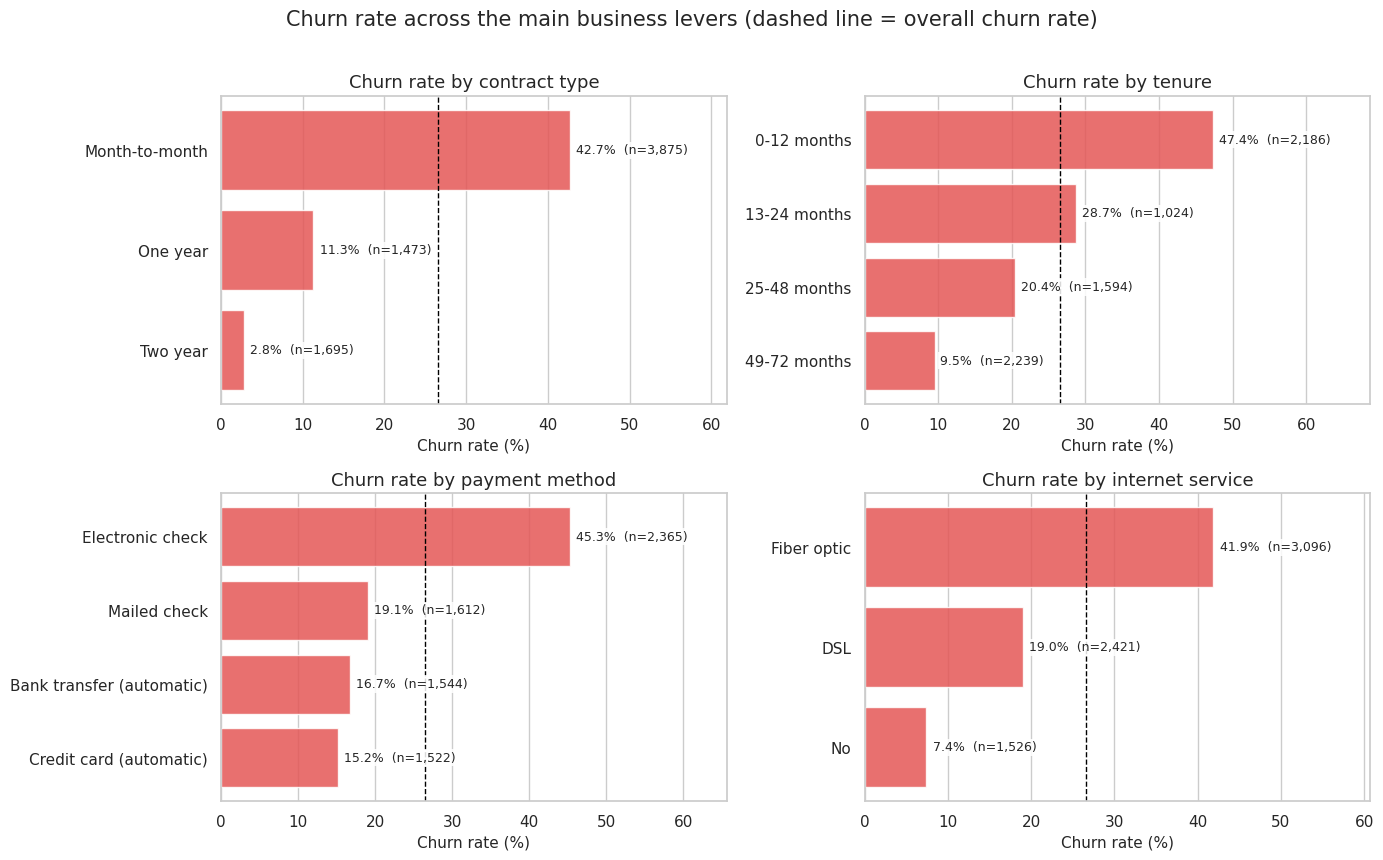

,Contract,customers,churned,churn_rate
0,Month-to-month,3875,1655,42.7
1,One year,1473,166,11.3
2,Two year,1695,48,2.8


In [15]:
df_eda = df.assign(TenureGroup=pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                                      labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"]))

fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
plot_churn_rate(axes[0, 0], df_eda, "Contract", title="Churn rate by contract type")
plot_churn_rate(axes[0, 1], df_eda, "TenureGroup", order=["0-12 months", "13-24 months", "25-48 months", "49-72 months"],
                title="Churn rate by tenure")
plot_churn_rate(axes[1, 0], df_eda, "PaymentMethod", title="Churn rate by payment method")
plot_churn_rate(axes[1, 1], df_eda, "InternetService", title="Churn rate by internet service")
fig.suptitle("Churn rate across the main business levers (dashed line = overall churn rate)", fontsize=15, y=1.01)
plt.tight_layout()
save_chart(fig, "04_churn_by_contract_or_key_features.png")
plt.show()

churn_rate_table(df_eda, "Contract")

Fiber-optic customers pay more than DSL customers, and contract type is also linked to the services people choose. So a single bar can mix several effects. To check whether the contract pattern holds *within* each internet-service type, we cross the two:

In [16]:
rate_by_contract_internet = (df.pivot_table(index="Contract", columns="InternetService", values="ChurnFlag", aggfunc="mean")
                               .mul(100).round(1))
customers_by_contract_internet = df.pivot_table(index="Contract", columns="InternetService", values="ChurnFlag", aggfunc="size")

print("Churn rate (%) by contract and internet service:")
display(rate_by_contract_internet)
print("Number of customers in each cell:")
display(customers_by_contract_internet)

Churn rate (%) by contract and internet service:


InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,32.2,54.6,18.9
One year,9.3,19.3,2.5
Two year,1.9,7.2,0.8


Number of customers in each cell:


InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,1223,2128,524
One year,570,539,364
Two year,628,429,638


**What the chart shows.** Churn rate for each contract type, tenure band, payment method and internet service type.

**Patterns observed**

- **Contract** is the strongest single pattern in the data: month-to-month customers churn at 42.7% (3,875 customers, 55% of the base), one-year at 11.3% and two-year at 2.8%.
- **Tenure:** the churn rate falls steadily with time with the company: 47.4% in the first 12 months, 28.7% in months 13-24, 20.4% in months 25-48, and 9.5% beyond 48 months.
- **Payment method:** electronic-check payers churn at 45.3% (2,365 customers), versus 19.1% for mailed check, 16.7% for automatic bank transfer and 15.2% for automatic credit card.
- **Internet service:** fiber optic 41.9%, DSL 19.0%, no internet 7.4%.

**Do these patterns survive a fairer comparison?** The cross-table shows that they do not simply reflect one another. The contract effect holds inside every internet-service type (for fiber: 54.6% month-to-month vs 7.2% two-year; for DSL: 32.2% vs 1.9%), and fiber customers churn more than DSL customers within every contract type (month-to-month 54.6% vs 32.2%, one-year 19.3% vs 9.3%, two-year 7.2% vs 1.9%). The riskiest cell is **month-to-month fiber customers: 2,128 customers with a 54.6% churn rate**.

**Caution.** Contract type and tenure are linked (average tenure is 18.0 months on month-to-month, 42.0 on one-year and 56.7 on two-year contracts), and the data does not say whether people on longer contracts are simply less able to leave during the term. Electronic check may also be a stand-in for other customer traits. These are associations, not proven causes.

### 5.5 Correlation among numerical variables

Correlation (Pearson, from -1 to +1) measures how strongly two numeric variables move together in a straight-line way. We include `SeniorCitizen` and `Churn` as 0/1 values. Correlations with a 0/1 variable are rough summaries, and correlation does not imply causation.

Saved: charts/05_correlation_analysis.png


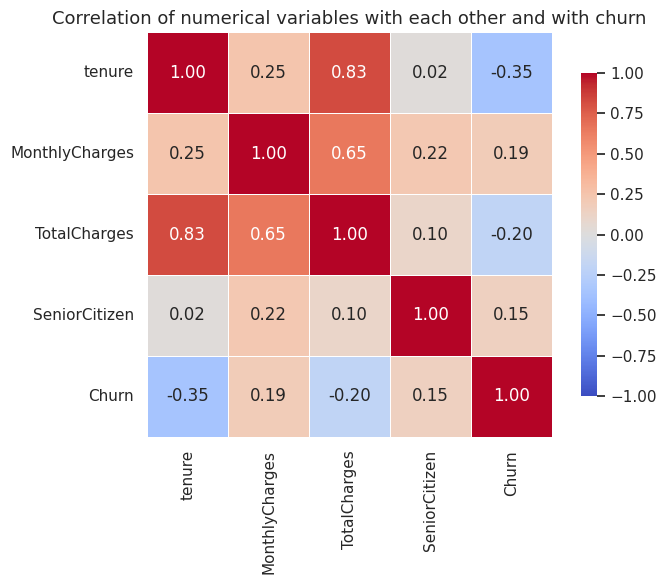

In [17]:
correlation_data = df[numeric_features].copy()
correlation_data["SeniorCitizen"] = (df["SeniorCitizen"] == "Yes").astype(int)
correlation_data["Churn"] = df["ChurnFlag"]
correlation_matrix = correlation_data.corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation of numerical variables with each other and with churn")
plt.tight_layout()
save_chart(fig, "05_correlation_analysis.png")
plt.show()

**What the chart shows.** Each cell is the correlation between two variables (red = move together, blue = move in opposite directions).

**Patterns observed**

- Correlation with churn is strongest for **tenure (-0.35)**: longer-standing customers churn less. `MonthlyCharges` is mildly positive (+0.19), `TotalCharges` mildly negative (-0.20) and `SeniorCitizen` +0.15. None is large, which fits the fact that the strongest patterns found so far (contract, internet service, payment method) are categorical and do not appear in this chart.
- **Tenure and TotalCharges are strongly related (0.83)**, and `MonthlyCharges` and `TotalCharges` less so (0.65), because total charges build up over time at the monthly rate.

**Why it matters for modelling.** `TotalCharges` overlaps heavily with the other two numeric features. A model can cope with this, but it makes individual coefficients unstable, which is why we read the Logistic Regression coefficients carefully in Section 10. Correlation only captures straight-line relationships and says nothing about causation.

## 6. Feature Engineering and Preprocessing

**What we are doing:** turning the cleaned table into inputs a model can use, and setting aside a test set.
**Why each step matters:**

- **Separate features and target.** `X` holds what we know about a customer; `y` is what we want to predict.
- **Remove `customerID`.** It is a random label that carries no real information about behaviour. Keeping it could let a model memorise individuals instead of learning patterns.
- **Drop the text `Churn` column.** It is the same information as the target (`ChurnFlag`). Leaving it in `X` would be **data leakage**: the model would be handed the answer.
- **Collapse redundant labels.** `No internet service` (in six columns) and `No phone service` (in `MultipleLines`) repeat what `InternetService` and `PhoneService` already say. If we keep them, those columns become exact copies of each other after one-hot encoding, which makes Logistic Regression coefficients hard to read. We recode them to `No`. The recode is a fixed rule that learns nothing from the data, so it is not leakage.
- **Encode categories.** Models need numbers. One-hot encoding turns a column such as `Contract` into separate 0/1 columns, one per category. Two-category columns (Yes/No) become a single 0/1 column.
- **Scale numeric features.** `StandardScaler` rescales numeric columns to a common range. Logistic Regression needs this (otherwise `TotalCharges`, in the thousands, would dominate `tenure`). Random Forest does not need it, but it does no harm, so both models share the same preprocessing for a fair comparison.
- **Stratified train/test split (80/20).** The test set simulates "new customers the model has never seen". Stratifying keeps the churn share the same in both parts.
- **Preprocessing inside a Pipeline.** *Data leakage* also happens if scaling or encoding is fitted on all the data before splitting, because test-set information then influences training. A Scikit-learn `Pipeline` fits the preprocessing on the training data only and then simply applies it to any new data.

**Class imbalance.** Only about a quarter of customers churn, so a model could look accurate by always predicting "stayed". We handle this in two ways: we use class weights (so mistakes on churners count more during training) and we judge models by precision, recall, F1 and ROC-AUC rather than accuracy. We deliberately do not oversample or synthesise data, because that is not needed for a first, explainable model.

In [18]:
# Inputs and target
X = df.drop(columns=["customerID", "Churn", "ChurnFlag"])
y = df["ChurnFlag"]

# Collapse the redundant labels to "No" (InternetService / PhoneService already carry that information)
redundant_label_columns = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
                           "StreamingTV", "StreamingMovies", "MultipleLines"]
X[redundant_label_columns] = X[redundant_label_columns].replace({"No internet service": "No", "No phone service": "No"})

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [c for c in X.columns if c not in numeric_features]

print(f"{X.shape[1]} input features: {len(numeric_features)} numeric, {len(categorical_features)} categorical")
print("Numeric:    ", numeric_features)
print("Categorical:", categorical_features)

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"\nTrain: {X_train.shape[0]:,} rows, churn rate {y_train.mean():.1%}")
print(f"Test:  {X_test.shape[0]:,} rows, churn rate {y_test.mean():.1%}")

19 input features: 3 numeric, 16 categorical
Numeric:     ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Train: 5,634 rows, churn rate 26.5%
Test:  1,409 rows, churn rate 26.5%


In [19]:
def build_preprocessor():
    """Scale numeric columns; one-hot encode categorical columns (binary columns become one 0/1 column)."""
    return ColumnTransformer([
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), categorical_features),
    ])


def build_pipeline(model):
    """Preprocessing + model in one object, so preprocessing is only ever fitted on training data."""
    return Pipeline([("preprocess", build_preprocessor()), ("model", model)])


# How many model input columns do we end up with after encoding?
example_preprocessor = build_preprocessor().fit(X_train)
print("Columns after preprocessing:", len(example_preprocessor.get_feature_names_out()))

Columns after preprocessing: 26


## 7. Establish a Baseline

**What and why:** a baseline is the simplest possible "model". Any real model must beat it to be worth using. We use Scikit-learn's `DummyClassifier(strategy="most_frequent")`, which ignores the features and predicts the majority class ("stayed") for every customer.

Because most customers stay, this do-nothing model will score a high **accuracy**, yet it will identify **zero** churners. That is exactly why accuracy alone is a poor yardstick for churn.

**How we compare models fairly.** We use **5-fold stratified cross-validation on the training set only** to compare the baseline and the models. The training data is split into 5 parts. The model is trained on 4 parts and scored on the remaining one, 5 times in turn. The test set stays untouched until the very end, so we never tune or choose anything using it.

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "Accuracy": "accuracy",
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": make_scorer(recall_score),
    "F1": make_scorer(f1_score, zero_division=0),
    "ROC-AUC": "roc_auc",
    "Avg Precision": "average_precision",
}

models = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
                                            random_state=RANDOM_STATE, n_jobs=-1),
}

# Cross-validate the baseline first
baseline_name = "Baseline (most frequent)"
baseline_cv = cross_validate(build_pipeline(models[baseline_name]), X_train, y_train, cv=cv, scoring=scoring)
pd.Series({metric: baseline_cv[f"test_{metric}"].mean() for metric in scoring}, name=baseline_name).round(3).to_frame().T

,Accuracy,Precision,Recall,F1,ROC-AUC,Avg Precision
Baseline (most frequent),0.735,0.0,0.0,0.0,0.5,0.265


**Result.** In cross-validation the baseline reaches an accuracy of **0.735** but a precision, recall and F1 of **0** and a ROC-AUC of **0.5** (no better than chance). It never identifies a single churner, and its average precision (0.265) simply equals the churn rate.

**What this tells us.** 0.735 is the accuracy to beat, but accuracy is the wrong yardstick here. A useful model must show a recall well above 0 and a ROC-AUC well above 0.5.

## 8. Train Machine Learning Models

We start with two well-known, complementary models.

**Logistic Regression.** A linear model that combines the features into a weighted score and converts it into a probability between 0 and 1. It is fast, hard to overfit, and its weights (coefficients) can be read and explained, which makes it a strong first choice for a business problem such as churn.

**Random Forest.** An ensemble of many decision trees, each trained on a random part of the data, whose votes are averaged. It can capture non-linear patterns and interactions between features (for example "short tenure *and* month-to-month contract") without being told about them, but it is harder to interpret.

Both use class weights to counter the class imbalance. Random Forest uses a few fixed, conservative settings (`min_samples_leaf=5` to stop trees memorising individual customers). We do **no hyperparameter tuning**; the aim is a clear, fair comparison.

In [21]:
cv_results = {baseline_name: baseline_cv}
for name, model in models.items():
    if name == baseline_name:
        continue
    cv_results[name] = cross_validate(build_pipeline(model), X_train, y_train, cv=cv, scoring=scoring)

cv_mean = pd.DataFrame({name: {metric: res[f"test_{metric}"].mean() for metric in scoring}
                        for name, res in cv_results.items()}).T
cv_std = pd.DataFrame({name: {metric: res[f"test_{metric}"].std() for metric in scoring}
                       for name, res in cv_results.items()}).T

# Show "mean (± std across the 5 folds)"
cv_display = cv_mean.round(3).astype(str) + " (±" + cv_std.round(3).astype(str) + ")"
print("5-fold cross-validation on the TRAINING set (mean ± std across folds)")
cv_display

5-fold cross-validation on the TRAINING set (mean ± std across folds)


,Accuracy,Precision,Recall,F1,ROC-AUC,Avg Precision
Baseline (most frequent),0.735 (±0.0),0.0 (±0.0),0.0 (±0.0),0.0 (±0.0),0.5 (±0.0),0.265 (±0.0)
Logistic Regression,0.749 (±0.014),0.518 (±0.017),0.803 (±0.037),0.629 (±0.021),0.846 (±0.012),0.66 (±0.02)
Random Forest,0.776 (±0.012),0.561 (±0.018),0.728 (±0.032),0.633 (±0.021),0.844 (±0.01),0.655 (±0.022)


**Reading the table.** Both models clearly beat the baseline on every churn-related metric.

| Model (CV, training set) | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Baseline | 0.735 | 0.000 | 0.000 | 0.000 | 0.500 |
| Logistic Regression | 0.749 | 0.518 | 0.803 | 0.629 | 0.846 |
| Random Forest | 0.776 | 0.561 | 0.728 | 0.633 | 0.844 |

- **Ranking ability is a tie.** ROC-AUC differs by 0.002, far less than the fold-to-fold variation (about ±0.01), and F1 is almost identical (0.629 vs 0.633).
- **The difference is in the type of mistake at the 0.5 cut-off.** Logistic Regression catches more churners (recall 0.803 vs 0.728) but flags more loyal customers by mistake (precision 0.518 vs 0.561). Random Forest is more cautious.

**Which model to use.** I select **Logistic Regression** as the working model, using the cross-validation results only (the test set has not been touched yet), for three reasons: (1) the models tie on ranking ability, (2) its higher recall fits the priority of not missing customers who are about to leave, and (3) it is far easier to explain, because its coefficients can be read directly. This is a judgment call, not a clear statistical win. If false alarms were expensive, Random Forest's higher precision and accuracy would be a fair argument for choosing it instead.

## 9. Model Evaluation

**What we are doing:** fitting each model on the full training set and, once, scoring it on the held-out test set.

How to read the metrics in a churn setting:

- **Accuracy**: share of all customers classified correctly. Misleading when most customers stay.
- **Precision**: of the customers the model *flags as churners*, how many really churned? Low precision means retention offers wasted on customers who would have stayed.
- **Recall**: of the customers who *really churned*, how many did the model catch? Low recall means at-risk customers slip through unnoticed.
- **F1-score**: a single number balancing precision and recall (their harmonic mean).
- **ROC-AUC**: how well the model *ranks* churners above non-churners, regardless of the cut-off. 0.5 is a coin flip, 1.0 is perfect ranking.
- **Average precision**: summarises the precision/recall trade-off across all cut-offs. Particularly informative when the positive class (churn) is the minority.

**Business meaning of the two error types**

- **False negative** (a real churner is predicted to stay): the company misses a chance to keep a customer. This is usually the more expensive mistake.
- **False positive** (a loyal customer is flagged): the company spends a retention offer or call it did not need to. Cheaper per case, but it adds up if there are many.

Predictions use the default cut-off: a customer is flagged as a churner if the predicted probability is at least 0.5.

In [22]:
def evaluate(fitted_model, features, target, threshold=0.5):
    """Common classification metrics for a fitted pipeline at a given probability threshold."""
    probability = fitted_model.predict_proba(features)[:, 1]
    prediction = (probability >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(target, prediction),
        "Precision": precision_score(target, prediction, zero_division=0),
        "Recall": recall_score(target, prediction),
        "F1": f1_score(target, prediction, zero_division=0),
        "ROC-AUC": roc_auc_score(target, probability),
        "Avg Precision": average_precision_score(target, probability),
    }


# Fit every pipeline on the training set and score once on the test set
fitted_models = {name: build_pipeline(model).fit(X_train, y_train) for name, model in models.items()}
test_results = pd.DataFrame({name: evaluate(fitted, X_test, y_test) for name, fitted in fitted_models.items()}).T

print("Held-out TEST set results (threshold = 0.5)")
test_results.round(3)

Held-out TEST set results (threshold = 0.5)


,Accuracy,Precision,Recall,F1,ROC-AUC,Avg Precision
Baseline (most frequent),0.735,0.000,0.000,0.000,0.500,0.265
Logistic Regression,0.739,0.505,0.786,0.615,0.842,0.634
Random Forest,0.777,0.561,0.735,0.637,0.845,0.650


In [23]:
# Class-specific performance (precision / recall / F1 for each class separately)
for name in ["Logistic Regression", "Random Forest"]:
    prediction = fitted_models[name].predict(X_test)
    print(f"=== {name} ===")
    print(classification_report(y_test, prediction, target_names=["Stayed (0)", "Churned (1)"], digits=3))

=== Logistic Regression ===
              precision    recall  f1-score   support

  Stayed (0)      0.903     0.722     0.802      1035
 Churned (1)      0.505     0.786     0.615       374

    accuracy                          0.739      1409
   macro avg      0.704     0.754     0.709      1409
weighted avg      0.798     0.739     0.753      1409

=== Random Forest ===
              precision    recall  f1-score   support

  Stayed (0)      0.892     0.792     0.839      1035
 Churned (1)      0.561     0.735     0.637       374

    accuracy                          0.777      1409
   macro avg      0.727     0.764     0.738      1409
weighted avg      0.804     0.777     0.785      1409



Saved: charts/06_model_comparison.png


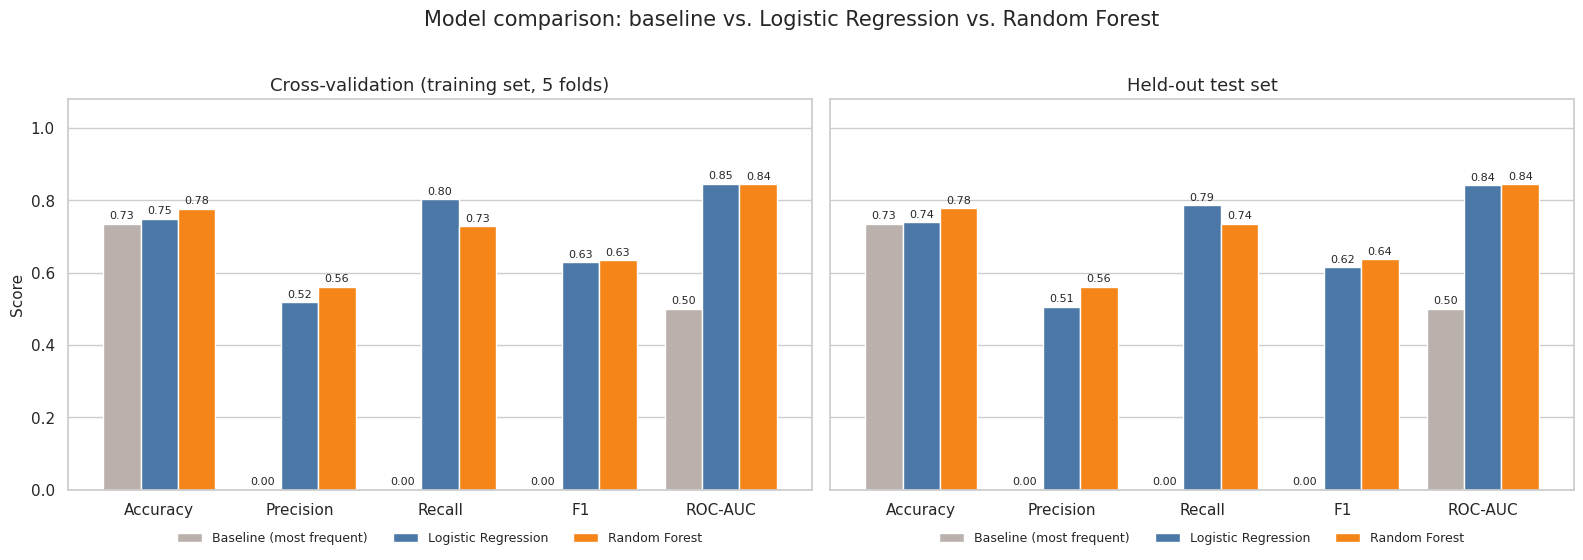

In [24]:
# Chart 06: model comparison (cross-validation on training data vs. held-out test data)
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
model_colors = ["#BAB0AC", "#4C78A8", "#F58518"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
for ax, (title, table) in zip(axes, [("Cross-validation (training set, 5 folds)", cv_mean),
                                     ("Held-out test set", test_results)]):
    plot_table = table[metrics_to_plot].T
    plot_table.plot(kind="bar", ax=ax, color=model_colors, width=0.8, edgecolor="white")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, 1.08)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="", loc="upper center", ncol=3, fontsize=9, bbox_to_anchor=(0.5, -0.08), frameon=False)
axes[0].set_ylabel("Score")
fig.suptitle("Model comparison: baseline vs. Logistic Regression vs. Random Forest", fontsize=15, y=1.02)
plt.tight_layout()
save_chart(fig, "06_model_comparison.png")
plt.show()

**Test-set results** (1,409 customers, of whom 374 churned):

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | Avg. precision |
|---|---|---|---|---|---|---|
| Baseline | 0.735 | 0.000 | 0.000 | 0.000 | 0.500 | 0.265 |
| Logistic Regression | 0.739 | 0.505 | 0.786 | 0.615 | 0.842 | 0.634 |
| Random Forest | 0.777 | 0.561 | 0.735 | 0.637 | 0.845 | 0.650 |

**Reading the results**

- **Test results agree with cross-validation** (for example Logistic Regression ROC-AUC 0.842 on the test set vs 0.846 in CV), so there is no sign that the models are overfitting the training data.
- **Accuracy hides the story.** Logistic Regression's accuracy (0.739) is barely above the baseline's (0.735), yet it finds 78.6% of churners where the baseline finds none.
- **Confusion matrices.** Logistic Regression caught 294 of the 374 churners and missed 80 (false negatives), but flagged 288 of the 1,035 loyal customers (false positives). Random Forest caught 275 and missed 99, while flagging 215 loyal customers. Moving from Logistic Regression to Random Forest avoids 73 false alarms but costs 19 additional missed churners.
- **Precision in plain words.** About half of the customers Logistic Regression flags (50.5%) really are leaving, and 56.1% for Random Forest.

**Preferred model.** I keep **Logistic Regression** for the reasons given in Section 8: equal ranking ability, higher recall (fewer missed churners) and easy interpretation. Random Forest scores slightly higher on test accuracy, precision and F1. With only 374 churners in the test set, differences of about 0.02 should not be over-read.

Saved: charts/07_confusion_matrix.png


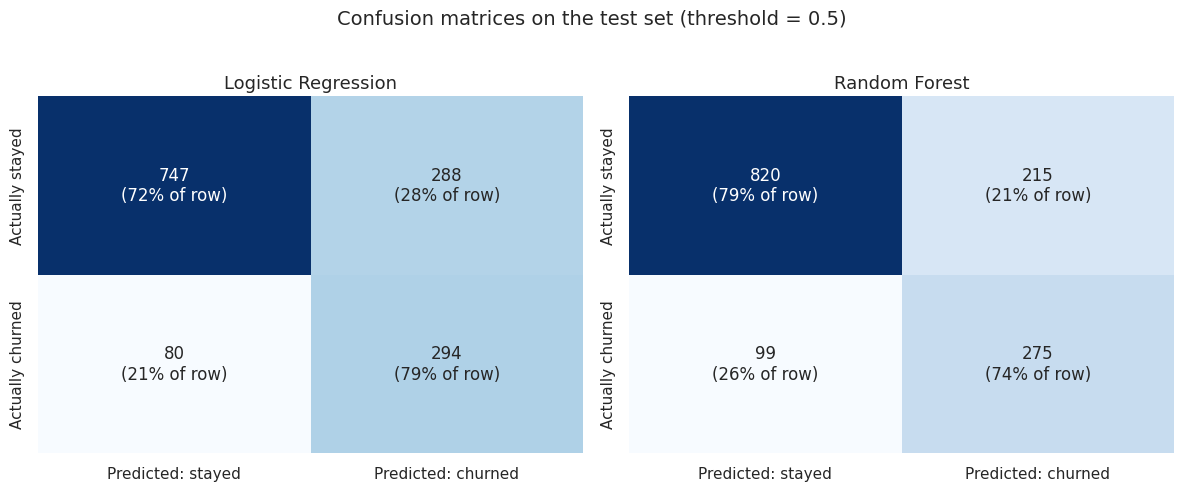

Logistic Regression  caught 294 churners, missed 80 (false negatives), flagged 288 loyal customers by mistake (false positives), correctly left alone 747
Random Forest        caught 275 churners, missed 99 (false negatives), flagged 215 loyal customers by mistake (false positives), correctly left alone 820


In [25]:
# Chart 07: confusion matrices (counts, with the share of each true class)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, name in zip(axes, ["Logistic Regression", "Random Forest"]):
    predicted = fitted_models[name].predict(X_test)
    matrix = confusion_matrix(y_test, predicted)
    row_share = matrix / matrix.sum(axis=1, keepdims=True) * 100
    annotations = np.array([[f"{matrix[i, j]:,}\n({row_share[i, j]:.0f}% of row)" for j in range(2)] for i in range(2)])
    sns.heatmap(matrix, annot=annotations, fmt="", cmap="Blues", cbar=False, ax=ax, annot_kws={"fontsize": 12},
                xticklabels=["Predicted: stayed", "Predicted: churned"],
                yticklabels=["Actually stayed", "Actually churned"])
    ax.set_title(name)
fig.suptitle("Confusion matrices on the test set (threshold = 0.5)", fontsize=14, y=1.02)
plt.tight_layout()
save_chart(fig, "07_confusion_matrix.png")
plt.show()

for name in ["Logistic Regression", "Random Forest"]:
    tn, fp, fn, tp = confusion_matrix(y_test, fitted_models[name].predict(X_test)).ravel()
    print(f"{name:20s} caught {tp} churners, missed {fn} (false negatives), "
          f"flagged {fp} loyal customers by mistake (false positives), correctly left alone {tn}")

Saved: charts/08_roc_curve.png


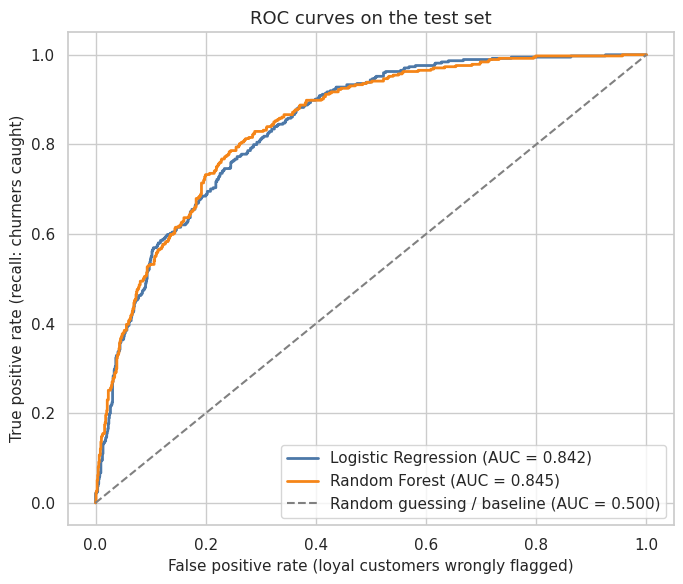

In [26]:
# Chart 08: ROC curves
fig, ax = plt.subplots(figsize=(7, 6))
for (name, fitted), color in zip(fitted_models.items(), model_colors):
    if name == baseline_name:
        continue
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, fitted.predict_proba(X_test)[:, 1])
    auc_value = test_results.loc[name, "ROC-AUC"]
    ax.plot(false_positive_rate, true_positive_rate, color=color, linewidth=2, label=f"{name} (AUC = {auc_value:.3f})")
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random guessing / baseline (AUC = 0.500)")
ax.set_xlabel("False positive rate (loyal customers wrongly flagged)")
ax.set_ylabel("True positive rate (recall: churners caught)")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right")
plt.tight_layout()
save_chart(fig, "08_roc_curve.png")
plt.show()

Saved: charts/10_precision_recall_curve.png


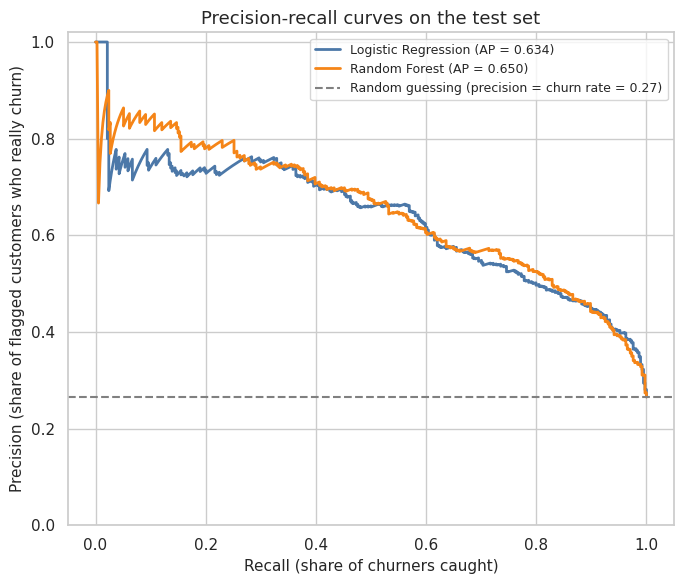

In [27]:
# Chart 10: precision-recall curves (more informative than ROC when the positive class is a minority)
prevalence = y_test.mean()
fig, ax = plt.subplots(figsize=(7, 6))
for (name, fitted), color in zip(fitted_models.items(), model_colors):
    if name == baseline_name:
        continue
    precision_values, recall_values, _ = precision_recall_curve(y_test, fitted.predict_proba(X_test)[:, 1])
    ap = test_results.loc[name, "Avg Precision"]
    ax.plot(recall_values, precision_values, color=color, linewidth=2, label=f"{name} (AP = {ap:.3f})")
ax.axhline(prevalence, color="grey", linestyle="--", label=f"Random guessing (precision = churn rate = {prevalence:.2f})")
ax.set_xlabel("Recall (share of churners caught)")
ax.set_ylabel("Precision (share of flagged customers who really churn)")
ax.set_title("Precision-recall curves on the test set")
ax.set_ylim(0, 1.02)
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
save_chart(fig, "10_precision_recall_curve.png")
plt.show()

**ROC curve.** Both models sit well above the diagonal (random guessing) and almost on top of each other (AUC 0.842 vs 0.845). In plain terms: pick one customer who churned and one who did not, and either model gives the churner the higher risk score about 84% of the time.

**Precision-recall curve.** This view is more informative when the positive class is a minority. Average precision is 0.634 for Logistic Regression and 0.650 for Random Forest, compared with 0.265 for random guessing (the churn rate), which is about 2.4 to 2.5 times better than chance. The curves show the trade-off directly: the more churners we try to catch (moving right), the lower the share of flagged customers who really churn.

### 9.1 Choosing the decision threshold (without touching the test set)

The 0.5 cut-off is a default, not a law. A lower cut-off flags more customers (higher recall, lower precision); a higher one flags fewer (higher precision, lower recall). The right balance depends on how costly a missed churner is compared with a wasted offer.

To explore this *without* peeking at the test set, we generate **out-of-fold predictions on the training data** (each training customer is scored by a model that never saw them) and look at precision and recall at several cut-offs.

In [28]:
# Working model, chosen from the cross-validation results in Section 8 (not from the test set).
# The two models tie on ROC-AUC, so the choice rests on recall and interpretability (explained in Section 8).
selected_name = "Logistic Regression"
print("Selected model:", selected_name)

out_of_fold_probability = cross_val_predict(build_pipeline(models[selected_name]), X_train, y_train,
                                            cv=cv, method="predict_proba")[:, 1]

threshold_rows = []
for threshold in np.arange(0.30, 0.76, 0.05):
    prediction = (out_of_fold_probability >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": round(threshold, 2),
        "Customers flagged (%)": round(prediction.mean() * 100, 1),
        "Precision": round(precision_score(y_train, prediction, zero_division=0), 3),
        "Recall": round(recall_score(y_train, prediction), 3),
        "F1": round(f1_score(y_train, prediction, zero_division=0), 3),
    })
threshold_table = pd.DataFrame(threshold_rows).set_index("Threshold")
threshold_table

Selected model: Logistic Regression


,Customers flagged (%),Precision,Recall,F1
Threshold,,,,
0.30,58.0,0.424,0.926,0.582
0.35,53.7,0.446,0.903,0.597
0.40,48.9,0.470,0.866,0.609
0.45,45.1,0.491,0.835,0.618
0.50,41.2,0.517,0.803,0.629
0.55,37.5,0.544,0.767,0.636
0.60,33.4,0.572,0.719,0.637
0.65,29.7,0.594,0.664,0.627
0.70,25.0,0.630,0.593,0.611


**Reading the table** (out-of-fold predictions on the 5,634 training customers):

- As the threshold rises from 0.30 to 0.75, the share of customers flagged drops from 58.0% to 20.8%, precision rises from 0.424 to 0.659, and recall falls from 0.926 to 0.516.
- **F1 is almost flat between 0.45 and 0.65 (0.618 to 0.637)**, so there is no sharp "best" threshold. The highest value is at 0.60 (F1 0.637, 33.4% flagged, precision 0.572, recall 0.719).

**Test set at two cut-offs** (table below). Moving to 0.60 raises precision (0.505 to 0.538) and accuracy (0.739 to 0.761) but lowers recall (0.786 to 0.703), and F1 does not improve (0.615 vs 0.610). The "best" cut-off from the training folds did not beat the default on the test set, which is what a flat F1 curve predicts.

**Takeaway.** The threshold is a business decision, not a statistical one. It depends on what a retention offer costs and what a retained customer is worth, and this dataset contains neither. We therefore keep the default **0.5** as the headline result and treat 0.60 as a lower-volume alternative (fewer customers contacted, fewer churners caught).

In [29]:
# Apply two cut-offs to the test set: the default (0.5) and the F1-maximising one found on training data.
f1_optimal_threshold = float(threshold_table["F1"].idxmax())
selected_model = fitted_models[selected_name]

final_comparison = pd.DataFrame({
    "Threshold 0.50 (default)": evaluate(selected_model, X_test, y_test, threshold=0.5),
    f"Threshold {f1_optimal_threshold:.2f} (best F1 on training folds)": evaluate(selected_model, X_test, y_test,
                                                                                    threshold=f1_optimal_threshold),
}).T
print(f"{selected_name}: test-set results at two cut-offs")
final_comparison.round(3)

Logistic Regression: test-set results at two cut-offs


,Accuracy,Precision,Recall,F1,ROC-AUC,Avg Precision
Threshold 0.50 (default),0.739,0.505,0.786,0.615,0.842,0.634
Threshold 0.60 (best F1 on training folds),0.761,0.538,0.703,0.610,0.842,0.634


In [30]:
# How useful is the ranking for prioritising outreach? Sort test customers from highest to lowest risk.
selected_probability = selected_model.predict_proba(X_test)[:, 1]
ranked = pd.DataFrame({"probability": selected_probability, "churned": y_test.to_numpy()}) \
           .sort_values("probability", ascending=False).reset_index(drop=True)
total_churners = ranked["churned"].sum()
overall_churn_rate = ranked["churned"].mean()

gain_rows = []
for share in [0.10, 0.20, 0.30, 0.50]:
    top = ranked.head(int(round(len(ranked) * share)))
    gain_rows.append({
        "Highest-risk customers contacted": f"top {int(share * 100)}%",
        "Customers": len(top),
        "Churners in this group": int(top["churned"].sum()),
        "Share of ALL churners reached (%)": round(top["churned"].sum() / total_churners * 100, 1),
        "Churn rate in this group (%)": round(top["churned"].mean() * 100, 1),
        "Lift vs. random": round(top["churned"].mean() / overall_churn_rate, 2),
    })
pd.DataFrame(gain_rows).set_index("Highest-risk customers contacted")

,Customers,Churners in this group,Share of ALL churners reached (%),Churn rate in this group (%),Lift vs. random
Highest-risk customers contacted,,,,,
top 10%,141,106,28.3,75.2,2.83
top 20%,282,186,49.7,66.0,2.48
top 30%,423,243,65.0,57.4,2.16
top 50%,704,327,87.4,46.4,1.75


**What the table shows.** If we rank the 1,409 test customers from highest to lowest predicted risk and contact only the top slice:

- **Top 10% (141 customers):** 106 are real churners (75.2% churn rate, 2.83 times the overall rate), reaching 28.3% of all churners.
- **Top 20% (282 customers):** 186 churners (66.0%), reaching 49.7% of all churners (lift 2.48).
- **Top 30% (423 customers):** 243 churners (57.4%), reaching 65.0% (lift 2.16).
- **Top 50% (704 customers):** 327 churners (46.4%), reaching 87.4% (lift 1.75).

So a team able to contact only 20% of customers would reach about half of all churners using the model's ranking, versus about 20% by picking customers at random. This shows how well the model *finds* at-risk customers. It does not show whether a retention offer would change their decision.

## 10. Feature Importance and Interpretation

**What we are doing:** asking which features the model relies on.
**Why:** a churn model is only useful to a business if people can understand and trust what drives it, and the answer should roughly agree with the EDA.

We use two complementary views:

1. **Permutation importance** (works for any model). We shuffle one original feature at a time on the test set and measure how much the ROC-AUC drops. A big drop means the model leans on that feature. Because it shuffles the *original* columns, a feature like `Contract` is judged as a whole rather than as separate one-hot columns.
2. **Logistic Regression coefficients.** Each coefficient is the change in the *log-odds* of churn, holding the other features fixed: per 1 standard deviation for numeric features, and for being in that category for categorical ones. Positive pushes toward churn, negative toward staying; `exp(coefficient)` is the *odds ratio*. Columns with more than two categories (such as `InternetService`) keep every category and the model applies regularisation, so read these as direction and rough strength, not exact effect sizes.

**Caution.** Both show what the model uses to *predict*. They do not prove what *causes* churn. Features that overlap (for example `MonthlyCharges` depends on which services someone has, and `TotalCharges` is roughly `tenure × MonthlyCharges`) share credit in unstable ways, so individual coefficients should be read with care.

Saved: charts/09_feature_importance.png


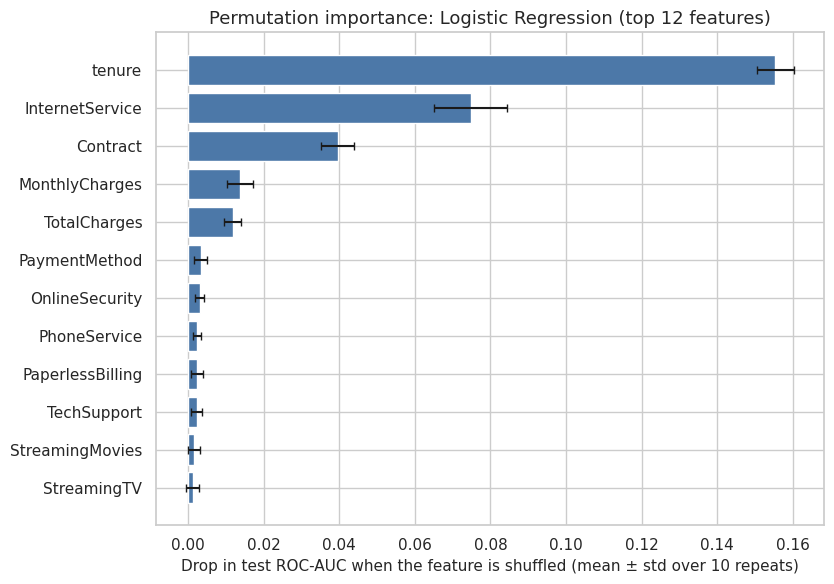

,feature,auc_drop_mean,auc_drop_std
0,tenure,0.1554,0.0048
1,InternetService,0.0747,0.0098
2,Contract,0.0395,0.0042
3,MonthlyCharges,0.0137,0.0035
4,TotalCharges,0.0119,0.0022
5,PaymentMethod,0.0033,0.0017
6,OnlineSecurity,0.0030,0.0012
7,PhoneService,0.0025,0.0010
8,PaperlessBilling,0.0024,0.0015
9,TechSupport,0.0023,0.0015


In [31]:
permutation = permutation_importance(selected_model, X_test, y_test, scoring="roc_auc", n_repeats=10,
                                     random_state=RANDOM_STATE, n_jobs=-1)
importance_table = (pd.DataFrame({"feature": X_test.columns,
                                  "auc_drop_mean": permutation.importances_mean,
                                  "auc_drop_std": permutation.importances_std})
                      .sort_values("auc_drop_mean", ascending=False).reset_index(drop=True))

top_n = 12
top_features = importance_table.head(top_n).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(top_features["feature"], top_features["auc_drop_mean"], xerr=top_features["auc_drop_std"],
        color="#4C78A8", capsize=3)
ax.set_xlabel("Drop in test ROC-AUC when the feature is shuffled (mean ± std over 10 repeats)")
ax.set_title(f"Permutation importance: {selected_name} (top {top_n} features)")
plt.tight_layout()
save_chart(fig, "09_feature_importance.png")
plt.show()

importance_table.head(top_n).round(4)

Saved: charts/11_logistic_regression_coefficients.png


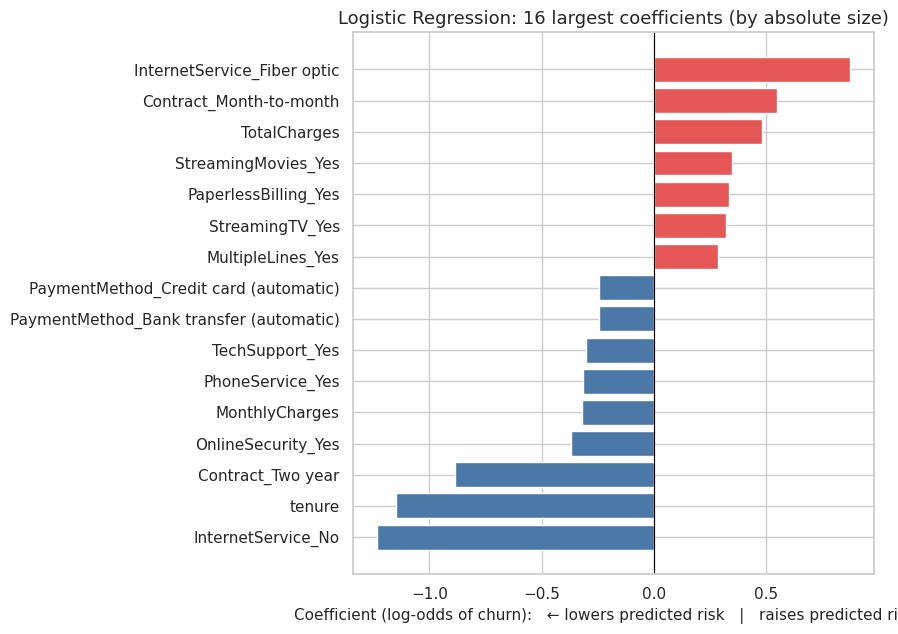

,feature,coefficient,odds_ratio
0,InternetService_Fiber optic,0.877,2.404
1,Contract_Month-to-month,0.550,1.732
2,TotalCharges,0.483,1.621
3,StreamingMovies_Yes,0.349,1.418
4,PaperlessBilling_Yes,0.336,1.400
5,StreamingTV_Yes,0.323,1.382
6,MultipleLines_Yes,0.288,1.334
7,PaymentMethod_Credit card (automatic),-0.243,0.784
8,PaymentMethod_Bank transfer (automatic),-0.243,0.784
9,TechSupport_Yes,-0.302,0.739


In [32]:
# Chart 11: Logistic Regression coefficients (largest positive and negative effects)
logistic_pipeline = fitted_models["Logistic Regression"]
coefficient_table = pd.DataFrame({
    "feature": logistic_pipeline.named_steps["preprocess"].get_feature_names_out(),
    "coefficient": logistic_pipeline.named_steps["model"].coef_[0],
})
coefficient_table["feature"] = coefficient_table["feature"].str.replace("numeric__", "", regex=False) \
                                                           .str.replace("categorical__", "", regex=False)
coefficient_table["odds_ratio"] = np.exp(coefficient_table["coefficient"])

# The 16 coefficients with the largest absolute size
extremes = coefficient_table.loc[coefficient_table["coefficient"].abs().nlargest(16).index].sort_values("coefficient")

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(extremes["feature"], extremes["coefficient"],
        color=np.where(extremes["coefficient"] > 0, CHURN_COLORS["Yes"], CHURN_COLORS["No"]))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coefficient (log-odds of churn):   \u2190 lowers predicted risk   |   raises predicted risk \u2192")
ax.set_title("Logistic Regression: 16 largest coefficients (by absolute size)")
plt.tight_layout()
save_chart(fig, "11_logistic_regression_coefficients.png")
plt.show()

extremes.sort_values("coefficient", ascending=False)[["feature", "coefficient", "odds_ratio"]].round(3).reset_index(drop=True)

### Permutation importance (selected model, test set)

- **Tenure is by far the most important feature:** shuffling it lowers the ROC-AUC by about 0.155.
- Next come **InternetService (about 0.075)** and **Contract (about 0.040)**, then `MonthlyCharges` (0.014) and `TotalCharges` (0.012).
- Every other feature contributes about 0.003 or less individually. In particular, `PaymentMethod` ranks low even though electronic-check customers churn a lot (45.3%). Once tenure, contract and internet service are known, payment method adds little extra predictive information.

So the model's predictive power rests mainly on five features, in line with the EDA (tenure, contract, internet service).

### Logistic Regression coefficients

- **Raise predicted churn risk:** fiber-optic internet (+0.88, odds ratio 2.40), month-to-month contract (+0.55, odds ratio 1.73), `TotalCharges` (+0.48), streaming movies and TV, paperless billing, multiple lines and, more weakly, electronic check (+0.16).
- **Lower predicted risk:** having no internet service (-1.23), longer tenure (-1.15 per standard deviation), a two-year contract (-0.89), online security (-0.37), tech support (-0.30), and automatic payment methods (about -0.24).

This agrees with the EDA on the main drivers.

### Reading these results carefully

- **Associations, not causes.** The model uses these features to predict churn. It does not prove that, for example, fiber optic *causes* customers to leave.
- **Overlapping features give odd signs.** `MonthlyCharges` has a negative coefficient (-0.32) although its simple correlation with churn is positive (+0.19), and `TotalCharges` is positive although its simple correlation is negative. Likewise, streaming subscribers churn slightly *less* than non-subscribers in the EDA, yet the streaming coefficients are positive. Coefficients describe the effect of a feature *with the other features held fixed*, and here the features overlap (monthly charges depend on which services a customer has; total charges are roughly tenure times monthly charges). These sign flips are a symptom of overlapping features and not business insights, so we should not read them as "higher bills reduce churn".

## 11. Business Insights and Recommendations

**What we are doing:** converting findings into actions, each tied to evidence from this notebook.

First, a descriptive table of the customer segments that the EDA and model point to. Churn rates here are measured directly in the data (all 7,043 customers), and the share of all churners tells us how much of the total problem each segment represents.

In [33]:
segments = {
    "All customers": pd.Series(True, index=df.index),
    "Month-to-month contract": df["Contract"].eq("Month-to-month"),
    "Tenure of 12 months or less": df["tenure"].le(12),
    "Fiber optic internet": df["InternetService"].eq("Fiber optic"),
    "Pays by electronic check": df["PaymentMethod"].eq("Electronic check"),
    "Internet customers without TechSupport": df["TechSupport"].eq("No"),
    "Month-to-month AND tenure <= 12 months": df["Contract"].eq("Month-to-month") & df["tenure"].le(12),
    "Month-to-month AND fiber optic AND electronic check": (df["Contract"].eq("Month-to-month")
                                                            & df["InternetService"].eq("Fiber optic")
                                                            & df["PaymentMethod"].eq("Electronic check")),
    "Two-year contract": df["Contract"].eq("Two year"),
}
total_churners_all = df["ChurnFlag"].sum()
segment_rows = []
for label, mask in segments.items():
    group = df[mask]
    segment_rows.append({
        "Segment": label,
        "Customers": len(group),
        "% of customers": round(len(group) / len(df) * 100, 1),
        "Churn rate (%)": round(group["ChurnFlag"].mean() * 100, 1),
        "% of all churners": round(group["ChurnFlag"].sum() / total_churners_all * 100, 1),
    })
pd.DataFrame(segment_rows).set_index("Segment")

,Customers,% of customers,Churn rate (%),% of all churners
Segment,,,,
All customers,7043,100.0,26.5,100.0
Month-to-month contract,3875,55.0,42.7,88.6
Tenure of 12 months or less,2186,31.0,47.4,55.5
Fiber optic internet,3096,44.0,41.9,69.4
Pays by electronic check,2365,33.6,45.3,57.3
Internet customers without TechSupport,3473,49.3,41.6,77.4
Month-to-month AND tenure <= 12 months,1994,28.3,51.4,54.8
Month-to-month AND fiber optic AND electronic check,1307,18.6,60.4,42.2
Two-year contract,1695,24.1,2.8,2.6


Each recommendation below is tied to a finding above. Where a recommendation relies on an idea that the data cannot confirm, it is marked **needs testing**.

| # | Finding in the data | Recommendation | Status |
|---|---|---|---|
| 1 | Month-to-month customers churn at 42.7% vs 11.3% (one-year) and 2.8% (two-year). They are 55.0% of customers but 88.6% of all churners. | Focus retention effort on month-to-month customers, for example offers to move to a one- or two-year contract. | Pattern is observed. **Needs testing:** whether the offers reduce churn, and whether customers who choose longer contracts differ from those who do not. |
| 2 | Churn is 47.4% in the first 12 months and falls with tenure. 55.5% of all churners have a tenure of 12 months or less. | Add early-life contact in the first year (onboarding check-ins, early support follow-up). | Pattern is observed. **Needs testing:** which early-life actions help. |
| 3 | Fiber-optic customers churn at 41.9% vs 19.0% for DSL, and also churn more within every contract type. They account for 69.4% of churners. | Investigate the fiber customer experience (price, reliability, competing offers) with satisfaction surveys or exit interviews. | The data shows *where* churn is high, not *why*. **Needs testing/further research.** |
| 4 | Electronic-check payers churn at 45.3% vs 15.2% to 19.1% for other methods, and make up 57.3% of churners. | Try encouraging a switch to automatic payment. | Pattern is observed, but the payment method may be a proxy for other traits. **Needs testing.** |
| 5 | Internet customers without tech support churn at 41.6% (15.2% with it); without online security 41.8% (14.6% with it). | Test offering trials of support or security services to at-risk internet customers. | Association only; engaged customers may simply be more likely to buy add-ons. **Needs testing.** |
| 6 | The riskiest segment (month-to-month, fiber optic and electronic check) has 1,307 customers (18.6%) with a 60.4% churn rate, and accounts for 42.2% of all churners. | Treat this group as the first priority for retention campaigns. | Observed in the data. |
| 7 | On the test set, contacting the top 20% of customers by predicted risk reaches 49.7% of all churners (lift 2.48). | Use the model's risk score to rank customers for outreach, with the cut-off set by budget and costs (Section 9.1). | Ranking ability is demonstrated on held-out data. The effect of acting on it is **not**. |

**How to evaluate a retention offer.** The model tells us *who is likely to leave*, not *whether an offer will keep them*. The standard way to find out is an A/B test: randomly split the flagged customers into a group that receives the offer and a control group that does not, then compare how many leave over a fixed period. This also measures the cost of offers made to customers who would have stayed anyway (the false positives). We have no cost or revenue data here, so this project makes no claims about financial savings.

## 12. Limitations and Future Improvements

**Limitations**

- **Data origin and representativeness.** The file has 7,043 customers from a single snapshot, and its source, time period, region and whether it is real or synthetic are unknown. Results may not transfer to another company or market.
- **Snapshot and timing.** There are no dates, so we cannot do a time-based validation (train on the past, test on the future). For customers who left, `tenure` is how long they stayed before leaving, so the model learns from a picture taken after the outcomes were known. In real use it would have to predict *future* churn using only information available beforehand, so the metrics here may be optimistic.
- **Missing information.** The data has no satisfaction scores, complaints, network quality, usage, competitor offers, price changes, age or location, and no reasons for leaving, all likely churn drivers. The model can only use what is recorded.
- **Class imbalance.** About 26.5% of customers churned. We used class weights, not resampling, and precision at a given cut-off depends on that churn rate, so it would change if the real-world rate were different.
- **Limited evaluation.** One train/test split with 374 test churners means the test metrics carry uncertainty (we computed no confidence intervals), and differences of about 0.02 between models should not be over-read. Models used fixed, untuned settings by design.
- **Interpretation limits.** Feature importance and coefficients show associations the model uses to predict, not causes, and overlapping features make individual coefficients unreliable.
- **No real-world test.** Nothing in this project shows that acting on the predictions reduces churn. There is no deployment, and none is claimed.

**Reasonable next steps**

1. Add uncertainty estimates (for example repeated cross-validation or bootstrapping the test set) before comparing models.
2. Try a gradient-boosting model and light hyperparameter tuning, using cross-validation only.
3. Replace the generic threshold with a cost-based one once the cost of an offer and the value of a retained customer are known, and check that predicted probabilities are well calibrated.
4. If dated data is available, validate over time; and design the A/B test described in Section 11.

## 13. Final Summary

In [34]:
# Pull the headline numbers directly from the results above so the summary can never drift from the analysis
selected_test = test_results.loc[selected_name]
baseline_test = test_results.loc[baseline_name]
print(f"Dataset: {len(df):,} customers, {X.shape[1]} input features, churn rate {df['ChurnFlag'].mean():.1%}")
print(f"Train/test: {len(X_train):,} / {len(X_test):,} (stratified)")
print(f"Baseline accuracy {baseline_test['Accuracy']:.3f}, recall {baseline_test['Recall']:.3f}")
print(f"Selected model: {selected_name}")
print(f"  Test ROC-AUC {selected_test['ROC-AUC']:.3f} | recall {selected_test['Recall']:.3f} | "
      f"precision {selected_test['Precision']:.3f} | F1 {selected_test['F1']:.3f} | accuracy {selected_test['Accuracy']:.3f}")
print("Top permutation-importance features:", ", ".join(importance_table["feature"].head(5)))

Dataset: 7,043 customers, 19 input features, churn rate 26.5%
Train/test: 5,634 / 1,409 (stratified)
Baseline accuracy 0.735, recall 0.000
Selected model: Logistic Regression
  Test ROC-AUC 0.842 | recall 0.786 | precision 0.505 | F1 0.615 | accuracy 0.739
Top permutation-importance features: tenure, InternetService, Contract, MonthlyCharges, TotalCharges


**Business problem.** A telecom company loses customers and wants to know who tends to leave and which customers to contact first. This project analysed 7,043 customers (26.5% churned) and built a model to estimate each customer's churn risk.

**Main patterns found** (associations, not proven causes)
- Churn is concentrated among **month-to-month customers** (42.7% churn, 88.6% of all churners), **new customers** (47.4% churn in the first 12 months), **fiber-optic customers** (41.9%), and **electronic-check payers** (45.3%).
- The lowest churn is among two-year contracts (2.8%), long-tenure customers (9.5% beyond 48 months) and customers with no internet service (7.4%).
- The highest-risk segment found (month-to-month, fiber optic, electronic check) has a 60.4% churn rate and holds 42.2% of all churners.

**Models evaluated.** A do-nothing baseline, Logistic Regression and Random Forest, all inside leakage-safe pipelines, compared with 5-fold cross-validation on the training set and evaluated once on a stratified 20% test set.

**Selected model and results.** **Logistic Regression**, selected on cross-validation results for its equal ranking ability to Random Forest, higher recall and easier interpretation. On the test set at a 0.5 threshold: **ROC-AUC 0.842, recall 0.786, precision 0.505, F1 0.615, accuracy 0.739**, against a baseline that catches no churners (accuracy 0.735, recall 0). Contacting the top 20% of customers by predicted risk reaches 49.7% of all churners (lift 2.48). Random Forest performed similarly (ROC-AUC 0.845, recall 0.735, precision 0.561, F1 0.637).

**Most useful recommendations.** Prioritise month-to-month customers, add early-life contact in the first year, investigate the fiber-optic customer experience, test nudges toward automatic payment and support/security offers, and use the model's risk ranking to prioritise outreach. All of these need an A/B test before anyone claims they reduce churn.

**What this project taught**
- **Accuracy can mislead:** a model that never finds a churner scored 73.5% accuracy.
- **Leakage prevention:** removing the ID and the text target, and fitting all preprocessing inside a Pipeline, keeps the test set honest.
- **Selection and testing are separate:** models were compared with cross-validation on the training data, and the test set was used once for the final result.
- **Thresholds are business decisions:** the F1-best cut-off was not better on the test set, and the right cut-off depends on costs we do not have.
- **Association is not causation:** feature importance and coefficients describe prediction; overlapping features can produce misleading signs.